In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv.xls")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df = df.drop("customerID", axis=1)

In [5]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [6]:
label_encoder = LabelEncoder()

In [7]:
binary_cols = ['Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0})
df['gender'] = df['gender'].map({'Female': 0, 'Male': 1})
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   int64  
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   int64  
 3   Dependents        7043 non-null   int64  
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   int64  
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   int64  
 16  PaymentMethod     7043 non-null   object 


In [9]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.5,0
2,1,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,1,0,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1


In [10]:
df["TotalCharges"].value_counts()

TotalCharges
          11
20.2      11
19.75      9
20.05      8
19.9       8
          ..
6849.4     1
692.35     1
130.15     1
3211.9     1
6844.5     1
Name: count, Length: 6531, dtype: int64

In [11]:
categorical_cols = [
    'MultipleLines', 'InternetService', 'OnlineSecurity',
    'OnlineBackup', 'DeviceProtection', 'TechSupport',
    'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod'
]
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

In [12]:
df.describe()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,Churn
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.504756,0.162147,0.483033,0.299588,32.371149,0.903166,0.592219,64.761692,0.265370
std,0.500013,0.368612,0.499748,0.458110,24.559481,0.295752,0.491457,30.090047,0.441561
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.250000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,9.000000,1.000000,0.000000,35.500000,0.000000
50%,1.000000,0.000000,0.000000,0.000000,29.000000,1.000000,1.000000,70.350000,0.000000
75%,1.000000,0.000000,1.000000,1.000000,55.000000,1.000000,1.000000,89.850000,1.000000
max,1.000000,1.000000,1.000000,1.000000,72.000000,1.000000,1.000000,118.750000,1.000000


In [13]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
bool_cols = df.select_dtypes(include='bool').columns
df[bool_cols] = df[bool_cols].astype(int)

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   gender                                 7043 non-null   int64  
 1   SeniorCitizen                          7043 non-null   int64  
 2   Partner                                7043 non-null   int64  
 3   Dependents                             7043 non-null   int64  
 4   tenure                                 7043 non-null   int64  
 5   PhoneService                           7043 non-null   int64  
 6   PaperlessBilling                       7043 non-null   int64  
 7   MonthlyCharges                         7043 non-null   float64
 8   TotalCharges                           7032 non-null   float64
 9   Churn                                  7043 non-null   int64  
 10  MultipleLines_No phone service         7043 non-null   int64  
 11  Mult

In [15]:
df.describe()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,...,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7032.000000,7043.000000,...,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.504756,0.162147,0.483033,0.299588,32.371149,0.903166,0.592219,64.761692,2283.300441,0.265370,...,0.290217,0.216669,0.384353,0.216669,0.387903,0.209144,0.240664,0.216101,0.335794,0.228880
std,0.500013,0.368612,0.499748,0.458110,24.559481,0.295752,0.491457,30.090047,2266.771362,0.441561,...,0.453895,0.412004,0.486477,0.412004,0.487307,0.406726,0.427517,0.411613,0.472301,0.420141
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,18.250000,18.800000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,9.000000,1.000000,0.000000,35.500000,401.450000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.000000,0.000000,0.000000,0.000000,29.000000,1.000000,1.000000,70.350000,1397.475000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1.000000,0.000000,1.000000,1.000000,55.000000,1.000000,1.000000,89.850000,3794.737500,1.000000,...,1.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000
max,1.000000,1.000000,1.000000,1.000000,72.000000,1.000000,1.000000,118.750000,8684.800000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [16]:
df.columns

Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'PaperlessBilling', 'MonthlyCharges', 'TotalCharges',
       'Churn', 'MultipleLines_No phone service', 'MultipleLines_Yes',
       'InternetService_Fiber optic', 'InternetService_No',
       'OnlineSecurity_No internet service', 'OnlineSecurity_Yes',
       'OnlineBackup_No internet service', 'OnlineBackup_Yes',
       'DeviceProtection_No internet service', 'DeviceProtection_Yes',
       'TechSupport_No internet service', 'TechSupport_Yes',
       'StreamingTV_No internet service', 'StreamingTV_Yes',
       'StreamingMovies_No internet service', 'StreamingMovies_Yes',
       'Contract_One year', 'Contract_Two year',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='object')

In [17]:
df.isna().sum()

gender                                    0
SeniorCitizen                             0
Partner                                   0
Dependents                                0
tenure                                    0
PhoneService                              0
PaperlessBilling                          0
MonthlyCharges                            0
TotalCharges                             11
Churn                                     0
MultipleLines_No phone service            0
MultipleLines_Yes                         0
InternetService_Fiber optic               0
InternetService_No                        0
OnlineSecurity_No internet service        0
OnlineSecurity_Yes                        0
OnlineBackup_No internet service          0
OnlineBackup_Yes                          0
DeviceProtection_No internet service      0
DeviceProtection_Yes                      0
TechSupport_No internet service           0
TechSupport_Yes                           0
StreamingTV_No internet service 

In [18]:
df.isna().sum()

gender                                    0
SeniorCitizen                             0
Partner                                   0
Dependents                                0
tenure                                    0
PhoneService                              0
PaperlessBilling                          0
MonthlyCharges                            0
TotalCharges                             11
Churn                                     0
MultipleLines_No phone service            0
MultipleLines_Yes                         0
InternetService_Fiber optic               0
InternetService_No                        0
OnlineSecurity_No internet service        0
OnlineSecurity_Yes                        0
OnlineBackup_No internet service          0
OnlineBackup_Yes                          0
DeviceProtection_No internet service      0
DeviceProtection_Yes                      0
TechSupport_No internet service           0
TechSupport_Yes                           0
StreamingTV_No internet service 

In [19]:
import warnings
warnings.filterwarnings("ignore")

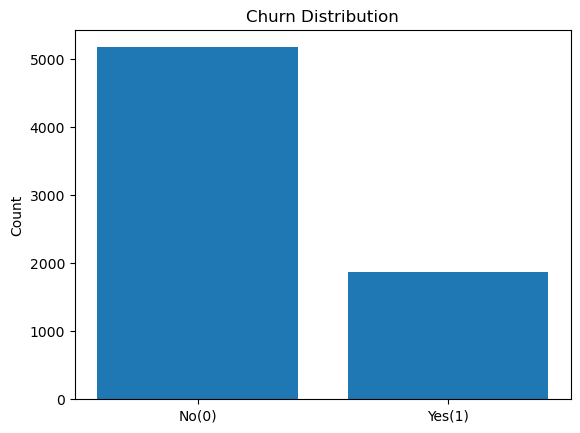

In [20]:
counts = df['Churn'].value_counts().sort_index()
plt.figure()
plt.bar(['No(0)', 'Yes(1)'], counts.values)
plt.title('Churn Distribution')
plt.ylabel('Count')
plt.show()

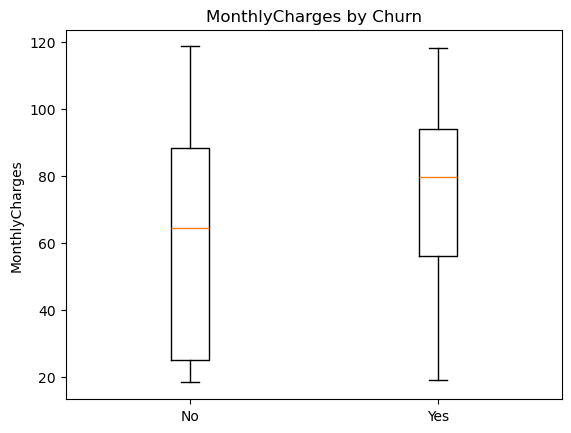

In [21]:
data = [df.loc[df['Churn']==0, 'MonthlyCharges'].dropna(),
        df.loc[df['Churn']==1, 'MonthlyCharges'].dropna()]
plt.figure()
plt.boxplot(data, labels=['No', 'Yes'])
plt.title('MonthlyCharges by Churn')
plt.ylabel('MonthlyCharges')
plt.show()

In [22]:
df = df.drop("TotalCharges", axis=1)

In [23]:
X = df.drop("Churn", axis=1)
y = df["Churn"]

In [24]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=15)

In [25]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [26]:
from sklearn.linear_model import LogisticRegression

In [27]:
logistic = LogisticRegression(max_iter = 2000, class_weight="balanced")
logistic.fit(X_train_scaled, y_train)
y_pred = logistic.predict(X_test_scaled)

In [28]:
y_pred

array([1, 0, 0, ..., 0, 0, 0], shape=(2113,))

In [29]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [30]:
score = accuracy_score(y_pred, y_test)
print("score: ", score)
print(classification_report(y_pred, y_test))
print("confusion matrix: \n", confusion_matrix(y_pred, y_test))

score:  0.7562707051585423
              precision    recall  f1-score   support

           0       0.74      0.90      0.82      1265
           1       0.79      0.54      0.64       848

    accuracy                           0.76      2113
   macro avg       0.77      0.72      0.73      2113
weighted avg       0.76      0.76      0.75      2113

confusion matrix: 
 [[1142  123]
 [ 392  456]]


ROC-AUC: 0.8401539767571208


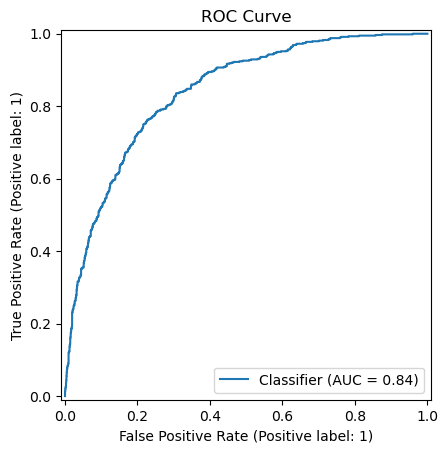

In [31]:
from sklearn.metrics import RocCurveDisplay, roc_auc_score
y_prob = logistic.predict_proba(X_test_scaled)[:,1]
print("ROC-AUC:", roc_auc_score(y_test, y_prob))
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.title('ROC Curve')
plt.show()

In [32]:
from sklearn.ensemble import RandomForestClassifier

In [33]:
rfc = RandomForestClassifier(n_estimators = 10, random_state = 15)
rfc.fit(X_train, y_train)

,n_estimators,10
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [34]:
y_pred = rfc.predict(X_test)

In [35]:
score = accuracy_score(y_pred, y_test)
print("score: ", score)
print(classification_report(y_pred, y_test))
print("confusion matrix: \n", confusion_matrix(y_pred, y_test))

score:  0.779460482725982
              precision    recall  f1-score   support

           0       0.91      0.81      0.86      1730
           1       0.43      0.65      0.52       383

    accuracy                           0.78      2113
   macro avg       0.67      0.73      0.69      2113
weighted avg       0.82      0.78      0.80      2113

confusion matrix: 
 [[1399  331]
 [ 135  248]]


In [36]:
from sklearn.ensemble import GradientBoostingClassifier

In [37]:
gb = GradientBoostingClassifier()
gb.fit(X_train, y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [38]:
y_pred = gb.predict(X_test)

In [39]:
score = accuracy_score(y_pred, y_test)
print("score: ", score)
print(classification_report(y_pred, y_test))
print("confusion matrix: \n", confusion_matrix(y_pred, y_test))

score:  0.795551348793185
              precision    recall  f1-score   support

           0       0.91      0.83      0.87      1678
           1       0.50      0.67      0.57       435

    accuracy                           0.80      2113
   macro avg       0.70      0.75      0.72      2113
weighted avg       0.82      0.80      0.81      2113

confusion matrix: 
 [[1390  288]
 [ 144  291]]


In [40]:
from sklearn.model_selection import GridSearchCV
parameters = {
    "loss" :  ["log_loss", "exponential"],
    "learning_rate" : [0.01, 0.05, 0.1],
    "n_estimators" : [100, 150, 180, 200],
    "max_depth" : [3,4,5],
    "subsample" : [0.8, 1.0]
}

In [41]:
grid_search = GridSearchCV(estimator=GradientBoostingClassifier(), param_grid = parameters, cv = 5, n_jobs = -1, verbose = 1)

In [42]:
grid_search.fit(X_train, y_train)

Fitting 5 folds for each of 144 candidates, totalling 720 fits


,estimator,GradientBoostingClassifier()
,param_grid,"{'learning_rate': [0.01, 0.05, ...], 'loss': ['log_loss', 'exponential'], 'max_depth': [3, 4, ...], 'n_estimators': [100, 150, ...], ...}"
,scoring,None
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,loss,'exponential'


In [43]:
grid_search.best_params_

{'learning_rate': 0.05,
 'loss': 'exponential',
 'max_depth': 3,
 'n_estimators': 150,
 'subsample': 0.8}

In [44]:
y_pred = grid_search.predict(X_test)
print("classification_report: ", classification_report(y_pred, y_test))
print("confusion_matrix: ", confusion_matrix(y_pred, y_test))

classification_report:                precision    recall  f1-score   support

           0       0.90      0.83      0.87      1673
           1       0.51      0.67      0.58       440

    accuracy                           0.80      2113
   macro avg       0.71      0.75      0.72      2113
weighted avg       0.82      0.80      0.81      2113

confusion_matrix:  [[1388  285]
 [ 146  294]]


In [45]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
def evaluate_classifier(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    return acc, prec, rec, f1
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
models = {
    "K Neighbors Classifier": KNeighborsClassifier(n_neighbors=7),
    "Decision Tree Classifier": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
    "Adaboost Classifier": AdaBoostClassifier(n_estimators=300, learning_rate=0.05, random_state=42),
    "XGBoost Classifier": XGBClassifier(eval_metric="logloss", random_state=42),
    "Support Vector Machine": SVC(kernel="rbf", class_weight="balanced", random_state=42)
}
for i in range(len(list(models))):
    name = list(models.keys())[i]
    model = list(models.values())[i]
    model.fit(X_train, y_train)
    y_train_pred = model.predict(X_train)
    y_test_pred  = model.predict(X_test)
    if y_train_pred.dtype.kind in "fc":
        y_train_pred = (y_train_pred >= 0.5).astype(int)
    if y_test_pred.dtype.kind in "fc":
        y_test_pred = (y_test_pred >= 0.5).astype(int)
    train_acc, train_prec, train_rec, train_f1 = evaluate_classifier(y_train, y_train_pred)
    test_acc,  test_prec,  test_rec,  test_f1  = evaluate_classifier(y_test,  y_test_pred)
    print(name)
    print("Model Performance for training set")
    print("Accuracy : ", train_acc)
    print("Precision: ", train_prec)
    print("Recall   : ", train_rec)
    print("F1 Score : ", train_f1)
    print("------------------------------------------------")
    print("Model Performance for test set")
    print("Accuracy : ", test_acc)
    print("Precision: ", test_prec)
    print("Recall   : ", test_rec)
    print("F1 Score : ", test_f1)
    print("------------------------------------------------\n")


K Neighbors Classifier
Model Performance for training set
Accuracy :  0.8271805273833671
Precision:  0.7085714285714285
Recall   :  0.5767441860465117
F1 Score :  0.6358974358974359
------------------------------------------------
Model Performance for test set
Accuracy :  0.7695220066256507
Precision:  0.6
Recall   :  0.47668393782383417
F1 Score :  0.5312800769971127
------------------------------------------------

Decision Tree Classifier
Model Performance for training set
Accuracy :  0.7523326572008113
Precision:  0.5162966461974492
Recall   :  0.8472868217054264
F1 Score :  0.6416201937188142
------------------------------------------------
Model Performance for test set
Accuracy :  0.73450070989115
Precision:  0.5100671140939598
Recall   :  0.7875647668393783
F1 Score :  0.6191446028513238
------------------------------------------------

Adaboost Classifier
Model Performance for training set
Accuracy :  0.7912778904665314
Precision:  0.7010785824345146
Recall   :  0.35271317829

* Decision Tree Classifier:

* In churn prediction, it is more important to focus on correctly identifying customers that are likely to churn rather than trying for high accuracy. The Decision Tree model correctly identified most customers that were likely to churn, as well as its reliability in terms of training and testing data.

* The simplicity of interpretability of the Decision Trees makes the model applicable in business decisions.

In [46]:
dt = DecisionTreeClassifier(
    max_depth=6,
    class_weight="balanced",
    random_state=42
)
dt.fit(X_train, y_train)
y_test_pred = dt.predict(X_test)
cm = confusion_matrix(y_test, y_test_pred)
print("Confusion Matrix:\n", cm)
print("Classification Report - Decision Tree Classifier\n")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Not Churn", "Churn"]
))

Confusion Matrix:
 [[1096  438]
 [ 123  456]]
Classification Report - Decision Tree Classifier

              precision    recall  f1-score   support

   Not Churn       0.90      0.71      0.80      1534
       Churn       0.51      0.79      0.62       579

    accuracy                           0.73      2113
   macro avg       0.70      0.75      0.71      2113
weighted avg       0.79      0.73      0.75      2113



In [47]:
import gradio as gr
import pandas as pd

model = grid_search.best_estimator_
feature_columns = X.columns.tolist()

def predict_churn(
    gender, senior_citizen, partner, dependents, tenure, phone_service,
    multiple_lines, internet_service, online_security, online_backup,
    device_protection, tech_support, streaming_tv, streaming_movies,
    contract, paperless_billing, payment_method, monthly_charges
):
    data = pd.DataFrame([{
        "gender": gender,
        "SeniorCitizen": int(senior_citizen),
        "Partner": partner,
        "Dependents": dependents,
        "tenure": float(tenure),
        "PhoneService": phone_service,
        "MultipleLines": multiple_lines,
        "InternetService": internet_service,
        "OnlineSecurity": online_security,
        "OnlineBackup": online_backup,
        "DeviceProtection": device_protection,
        "TechSupport": tech_support,
        "StreamingTV": streaming_tv,
        "StreamingMovies": streaming_movies,
        "Contract": contract,
        "PaperlessBilling": paperless_billing,
        "PaymentMethod": payment_method,
        "MonthlyCharges": float(monthly_charges)
    }])

    for col in feature_columns:
        if col not in data.columns:
            data[col] = 0

    data = data[feature_columns]
    prediction = model.predict(data)[0]
    probability = model.predict_proba(data)[0][1]

    result = "Likely to Churn" if prediction == 1 else "Likely to Stay"
    return {
        "Prediction": result,
        "Churn Probability": f"{probability:.2%}"
    }

inputs = [
    gr.Dropdown(["Female", "Male"], label="Gender", value="Male"),
    gr.Dropdown([0, 1], label="Senior Citizen", value=0),
    gr.Dropdown(["Yes", "No"], label="Partner", value="No"),
    gr.Dropdown(["Yes", "No"], label="Dependents", value="No"),
    gr.Number(label="Tenure (months)", value=12),
    gr.Dropdown(["Yes", "No"], label="Phone Service", value="Yes"),
    gr.Dropdown(["Yes", "No", "No phone service"], label="Multiple Lines", value="No"),
    gr.Dropdown(["DSL", "Fiber optic", "No"], label="Internet Service", value="Fiber optic"),
    gr.Dropdown(["Yes", "No", "No internet service"], label="Online Security", value="No"),
    gr.Dropdown(["Yes", "No", "No internet service"], label="Online Backup", value="No"),
    gr.Dropdown(["Yes", "No", "No internet service"], label="Device Protection", value="No"),
    gr.Dropdown(["Yes", "No", "No internet service"], label="Tech Support", value="No"),
    gr.Dropdown(["Yes", "No", "No internet service"], label="Streaming TV", value="No"),
    gr.Dropdown(["Yes", "No", "No internet service"], label="Streaming Movies", value="No"),
    gr.Dropdown(["Month-to-month", "One year", "Two year"], label="Contract", value="Month-to-month"),
    gr.Dropdown(["Yes", "No"], label="Paperless Billing", value="Yes"),
    gr.Dropdown(
        ["Electronic check", "Mailed check", "Bank transfer (automatic)", "Credit card (automatic)"],
        label="Payment Method",
        value="Electronic check"
    ),
    gr.Number(label="Monthly Charges", value=70.0)
]

demo = gr.Interface(
    fn=predict_churn,
    inputs=inputs,
    outputs=gr.JSON(label="Churn Prediction"),
    title="Telco Customer Churn Prediction",
    description="Enter customer details to predict churn probability."
)

demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
